# Stage 3 — Covariate Acquisition (Minimal Set)

**Goal:** pull the physical drivers needed to make the end-to-end pipeline run.

## Why only two predictors here
The full predictor roster (wind, waves, salinity, currents, SSH, MLD, optics) is **Stage 8**. Right now we want the *shortest path* from raw data to a trained model that beats persistence. Two predictors are enough to validate the whole pipeline — Stage 4 (supervised dataset), 5 (baselines), 6 (XGBoost), 7 (interpretability). If anything breaks in the pipeline, you want to discover it with 2 predictors, not 20.

Resist the temptation to download everything now.

## What we pull
1. **SST** — L3 Mediterranean sea-surface temperature, same box & period as the CHL cube.
2. **Bathymetry** — static water depth, regridded onto the CHL grid. We use NOAA ETOPO 2022 (1/30°, fully public via OPeNDAP) so the download is one xarray call, no manual GEBCO download required.

## What we *do not* do here
- Regridding onto the CHL grid → that lives in Stage 4 (`04-Build-Supervised`).
- ERA5 wind, CMEMS physics/waves/optics → Stage 8.
- We just sanity-check that each cube downloaded sanely and that the lon/lat conventions are compatible.

## 3.0 — Configuration

Same box and date window as Stage 1, copy-pasted for clarity.

In [3]:
from pathlib import Path

BOX = dict(
    minimum_longitude=12.0, maximum_longitude=15.5,
    minimum_latitude=35.5,  maximum_latitude=37.5,
)

START = "2021-01-01T00:00:00"
END   = "2023-12-31T00:00:00"

RAW_DIR = Path("data/raw")
RAW_DIR.mkdir(parents=True, exist_ok=True)

# L4 multi-year reanalysis SST for the Mediterranean — the only MY product available.
# There is no L3 multi-year Med SST (L3S is NRT-only), so we use L4 as a gap-free
# predictor. Methodologically fine: PLAN.md allows L4/model fields as inputs;
# the L3-only rule applies to the target (CHL), not predictors.
SST_DATASET_ID = "cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021"
SST_VARIABLES  = ["analysed_sst"]      # kelvin, ~5 km daily
SST_PATH       = RAW_DIR / "sst_malta_2021_2023.nc"

BATHY_PATH     = RAW_DIR / "bathy_malta.nc"

CHL_PATH       = RAW_DIR / "chl_malta_2021_2023.nc"
assert CHL_PATH.exists(), "Missing CHL cube — run 01-Data-Acquisition first."

## 3.1 — Confirm the SST dataset ID

We use `cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021` — the L4 multi-year Mediterranean SST reanalysis. The variable is `analysed_sst` (kelvin).

**Why L4, not L3?** The CMEMS Med catalogue has *no* L3 multi-year SST product — `SST_MED_SST_L3S_NRT_OBSERVATIONS_010_012_a/b` is the only L3S option and it is NRT only (doesn't cover 2021 historically). The L4 REP product is the historical workhorse.

**Is gap-filled SST as a predictor a problem?** No. PLAN.md is explicit that the no-interpolation rule applies to the *target* (CHL) only. Using gap-free reanalysis fields as *inputs* is the standard ocean-colour practice and is not circular — the model is never scored on reproducing SST.

If `describe` errors with *dataset not found*, run:
```powershell
copernicusmarine describe --contains "med_sst" --return-fields dataset_id
```
and update `SST_DATASET_ID` above to the current short-name.

In [4]:
import copernicusmarine

try:
    copernicusmarine.describe(dataset_id=SST_DATASET_ID)
    print(f"OK — {SST_DATASET_ID} is reachable.")
except Exception as e:
    print(f"FAIL — {SST_DATASET_ID}\n   {e}")
    print("\nRun  copernicusmarine describe --contains \"SST_MED\"  to list current IDs.")

Fetching catalogue 1: 100%|██████████| 2/2 [00:01<00:00,  1.72it/s]

OK — cmems_SST_MED_SST_L4_REP_OBSERVATIONS_010_021 is reachable.


## 3.2 — Download SST

Same idempotent pattern as Stage 1: skip if file exists, set `FORCE=True` to re-pull.

In [5]:
FORCE = False

if SST_PATH.exists() and not FORCE:
    size_mb = SST_PATH.stat().st_size / 1e6
    print(f"Skipping — {SST_PATH.name} exists ({size_mb:.1f} MB). Set FORCE=True to re-pull.")
else:
    copernicusmarine.subset(
        dataset_id=SST_DATASET_ID,
        variables=SST_VARIABLES,
        start_datetime=START,
        end_datetime=END,
        output_filename=SST_PATH.name,
        output_directory=str(RAW_DIR),
        **BOX,
    )
    print(f"Downloaded → {SST_PATH}  ({SST_PATH.stat().st_size/1e6:.1f} MB)")

INFO - 2026-05-29T17:33:14Z - Selected dataset version: "202411"
INFO - 2026-05-29T17:33:14Z - Selected dataset part: "default"
INFO - 2026-05-29T17:33:20Z - Total size of the download: 5.86 MB.


Downloaded → data\raw\sst_malta_2021_2023.nc  (6.2 MB)


## 3.3 — Inspect SST

Confirm units (°C vs K), sane range, and that the time/lat/lon coords line up roughly with the CHL cube.

In [6]:
import xarray as xr
import numpy as np

sst_ds = xr.open_dataset(SST_PATH, chunks={"time": 50})
sst_var = SST_VARIABLES[0]
sst = sst_ds[sst_var]

print("Variable :", sst_var)
print("Dims     :", dict(sst.sizes))
print("Time     :", str(sst.time.values.min())[:10], "→", str(sst.time.values.max())[:10])
print("Lat range:", float(sst.latitude.min()),  "→", float(sst.latitude.max()))
print("Lon range:", float(sst.longitude.min()), "→", float(sst.longitude.max()))
print("Units    :", sst.attrs.get("units"))

# Sample a tiny slice to read out values without forcing the whole cube into memory
sample = sst.isel(time=slice(0, 30)).values
print(f"\nSample (first 30 days) — min {np.nanmin(sample):.2f}  "
      f"median {np.nanmedian(sample):.2f}  max {np.nanmax(sample):.2f}")

Variable : analysed_sst
Dims     : {'time': 1095, 'latitude': 40, 'longitude': 70}
Time     : 2021-01-01 → 2023-12-31
Lat range: 35.54203414916992 → 37.49818801879883
Lon range: 12.002664566040039 → 15.45583724975586
Units    : kelvin

Sample (first 30 days) — min 287.79  median 289.32  max 292.29


## 3.4 — Bathymetry from NOAA ETOPO 2022 (via ERDDAP)

We use ETOPO 2022 at 15 arc-seconds (~460 m, finer than our 1 km CHL grid). The download goes through NOAA PIFSC's **ERDDAP** service, which subsets server-side and returns a small netCDF — no auth, no manual tile selection, no global file download.

Key facts about the data:
- Variable name: **`z`** (elevation in metres)
- Coords: `latitude`, `longitude` (same convention as the CHL cube — no rename needed later)
- Sign: **negative = below sea level**, positive = land. We'll flip the sign to a positive 'depth' in Stage 4.

> If PIFSC ERDDAP is unreachable from your network, see the fallback cell below for downloading GEBCO 2024 manually.

In [10]:
import urllib.request

FORCE_BATHY = False

# ERDDAP .nc endpoint — subsets server-side to our exact box. ~1.6 MB.
ERDDAP_URL = (
    "https://oceanwatch.pifsc.noaa.gov/erddap/griddap/ETOPO_2022_v1_15s.nc"
    f"?z[({BOX['minimum_latitude']}):({BOX['maximum_latitude']})]"
    f"[({BOX['minimum_longitude']}):({BOX['maximum_longitude']})]"
)

if BATHY_PATH.exists() and not FORCE_BATHY:
    print(f"Skipping — {BATHY_PATH.name} exists "
          f"({BATHY_PATH.stat().st_size/1e6:.2f} MB). Set FORCE_BATHY=True to re-pull.")
else:
    print("Downloading ETOPO 2022 subset from PIFSC ERDDAP…")
    print(f"URL: {ERDDAP_URL}")
    urllib.request.urlretrieve(ERDDAP_URL, BATHY_PATH)
    print(f"Saved → {BATHY_PATH}  ({BATHY_PATH.stat().st_size/1e6:.2f} MB)")

URL: https://oceanwatch.pifsc.noaa.gov/erddap/griddap/ETOPO_2022_v1_15s.nc?z[(35.5):(37.5)][(12.0):(15.5)]
Saved → data\raw\bathy_malta.nc  (1.63 MB)


In [11]:
bathy = xr.open_dataset(BATHY_PATH)
print(bathy)

# ETOPO ERDDAP gives us 'z' as the elevation variable. Stay defensive in case
# the user swapped to a GEBCO fallback below (which uses 'elevation').
elev_var = next(v for v in bathy.data_vars if v in ("z", "elevation", "bed_elevation"))
elev = bathy[elev_var]
print(f"\nElevation variable: {elev_var}")
print(f"Range  : {float(elev.min())} m to {float(elev.max())} m")
print(f"Median : {float(elev.median())} m   (should be a large negative number — open sea)")
print(f"Shape  : {dict(elev.sizes)}")

<xarray.Dataset> Size: 2MB
Dimensions:    (latitude: 481, longitude: 841)
Coordinates:
  * latitude   (latitude) float64 4kB 35.5 35.51 35.51 35.51 ... 37.49 37.5 37.5
  * longitude  (longitude) float64 7kB 12.0 12.01 12.01 ... 15.49 15.5 15.5
Data variables:
    z          (latitude, longitude) float32 2MB ...
Attributes: (12/38)
    cdm_data_type:                  Grid
    Conventions:                    CF-1.6, COARDS, ACDD-1.3
    creator_email:                  Barry.Eakins@noaa.gov
    creator_name:                   NOAA NCEI
    creator_type:                   institution
    creator_url:                    https://www.ngdc.noaa.gov/mgg/global/glob...
    ...                             ...
    standard_name_vocabulary:       CF Standard Name Table v70
    summary:                        ETOPO 2022, a global relief model with 15...
    sw_point_longitude:             0.02083333
    title:                          Bathymetry and Topography, NCEI ETOPO 202...
    Westernmost_East

### Fallback: GEBCO 2024 (manual)

If NOAA THREDDS is unreachable from your network, download the GEBCO 2024 *sub-ice topo/bathy* netcdf from <https://www.gebco.net/data_and_products/gridded_bathymetry_data/> (free, no login). Drop the file at `data/raw/GEBCO_2024.nc`, then run:

```python
gebco = xr.open_dataset('data/raw/GEBCO_2024.nc')
bathy = gebco.sel(lon=slice(12.0, 15.5), lat=slice(35.5, 37.5))
bathy.to_netcdf('data/raw/bathy_malta.nc')
```

Variable will be called `elevation`; same sign convention as ETOPO.

---
## Validation Gate 3

Five checks, all printed as PASS/FAIL by the cell below.

1. SST cube exists.
2. SST date range overlaps the CHL date range (so we can join later).
3. SST values are physically sane — Mediterranean SST is **13–28 °C** (or 286–301 K).
4. Bathymetry covers the box and depths are **negative** (or we know the sign).
5. CHL, SST and bathy all share the **same lon/lat conventions** (ascending vs descending lat is the classic silent bug — pcolormesh draws fine either way, then features land in the wrong pixels).

In [12]:
import numpy as np
import xarray as xr

chl_ds = xr.open_dataset(CHL_PATH, chunks={"time": 50})
chl    = chl_ds.CHL
sst_ds = xr.open_dataset(SST_PATH, chunks={"time": 50})
sst    = sst_ds[SST_VARIABLES[0]]
bathy  = xr.open_dataset(BATHY_PATH)
elev_var = next(v for v in bathy.data_vars if v in ("z", "elevation", "bed_elevation"))
elev   = bathy[elev_var]

# Bathy lat/lon may be named differently depending on source (ETOPO=latitude/longitude,
# some GEBCO files=lat/lon). Pick whichever exists.
bathy_lat_name = "latitude" if "latitude" in elev.coords else "lat"
bathy_lon_name = "longitude" if "longitude" in elev.coords else "lon"
bathy_lat = elev[bathy_lat_name]
bathy_lon = elev[bathy_lon_name]

results = {}

# 1) SST exists
results["SST file present"] = SST_PATH.exists() and SST_PATH.stat().st_size > 10_000

# 2) date overlap
chl_t0, chl_t1 = chl.time.values.min(), chl.time.values.max()
sst_t0, sst_t1 = sst.time.values.min(), sst.time.values.max()
overlap_start = max(chl_t0, sst_t0)
overlap_end   = min(chl_t1, sst_t1)
overlap_days  = (overlap_end - overlap_start) / np.timedelta64(1, "D")
results["CHL/SST overlap > 1 year"] = overlap_days > 365

# 3) SST physically plausible
sample = sst.isel(time=slice(0, 60)).values
smed = float(np.nanmedian(sample))
in_celsius = 10  <= smed <= 30
in_kelvin  = 283 <= smed <= 303
results["SST median in [10–30 °C] or [283–303 K]"] = in_celsius or in_kelvin

# 4) bathymetry sane
results["bathy covers the box"] = (
    float(bathy_lon.min()) <= 12.1 and float(bathy_lon.max()) >= 15.4 and
    float(bathy_lat.min()) <= 35.6 and float(bathy_lat.max()) >= 37.4
)
results["bathy has negative depths (ocean)"] = float(elev.min()) < -50

# 5) coord conventions
def is_ascending(arr):
    a = np.asarray(arr)
    return a[1] > a[0]

chl_lat_asc   = is_ascending(chl.latitude.values)
sst_lat_asc   = is_ascending(sst.latitude.values)
bathy_lat_asc = is_ascending(bathy_lat.values)
results["all three lat axes share orientation"] = (
    chl_lat_asc == sst_lat_asc == bathy_lat_asc
)

chl_lon_asc   = is_ascending(chl.longitude.values)
sst_lon_asc   = is_ascending(sst.longitude.values)
bathy_lon_asc = is_ascending(bathy_lon.values)
results["all three lon axes share orientation"] = (
    chl_lon_asc == sst_lon_asc == bathy_lon_asc
)

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(
    f"\nCHL    lat ascending? {chl_lat_asc}   lon ascending? {chl_lon_asc}"
    f"\nSST    lat ascending? {sst_lat_asc}   lon ascending? {sst_lon_asc}"
    f"\nBathy  lat ascending? {bathy_lat_asc}   lon ascending? {bathy_lon_asc}"
    f"\nSST median            : {smed:.2f}  ({'°C' if in_celsius else 'K' if in_kelvin else '??'})"
    f"\nBathy depth range     : {float(elev.min()):.0f} m to {float(elev.max()):.0f} m"
    f"\nCHL/SST overlap       : {overlap_days:.0f} days"
)

if all(results.values()):
    print("\nGate 3 PASSED — proceed to 04-Build-Supervised.")
else:
    print("\nGate 3 FAILED — common causes:")
    print("  • SST in Kelvin   → fine, but remember to convert in Stage 4")
    print("  • lat axes differ → use .sortby('latitude') on the odd-one-out")
    print("  • bathy positive  → flip sign with  elev = -elev  before saving")

PASS  SST file present
PASS  CHL/SST overlap > 1 year
PASS  SST median in [10–30 °C] or [283–303 K]
PASS  bathy covers the box
PASS  bathy has negative depths (ocean)
PASS  all three lat axes share orientation
PASS  all three lon axes share orientation

CHL    lat ascending? True   lon ascending? True
SST    lat ascending? True   lon ascending? True
Bathy  lat ascending? True   lon ascending? True
SST median            : 288.90  (K)
Bathy depth range     : -3060 m to 971 m
CHL/SST overlap       : 1094 days

Gate 3 PASSED — proceed to 04-Build-Supervised.


## 3.5 — Visual sanity (optional)

Plot a single SST day and the bathymetry. SST should show the seasonal warm pool offshore and a cooler coastal band; bathy should show the Sicilian shelf shallowing toward Cape Passero (NE corner) and the deep Strait of Sicily basin to the south.

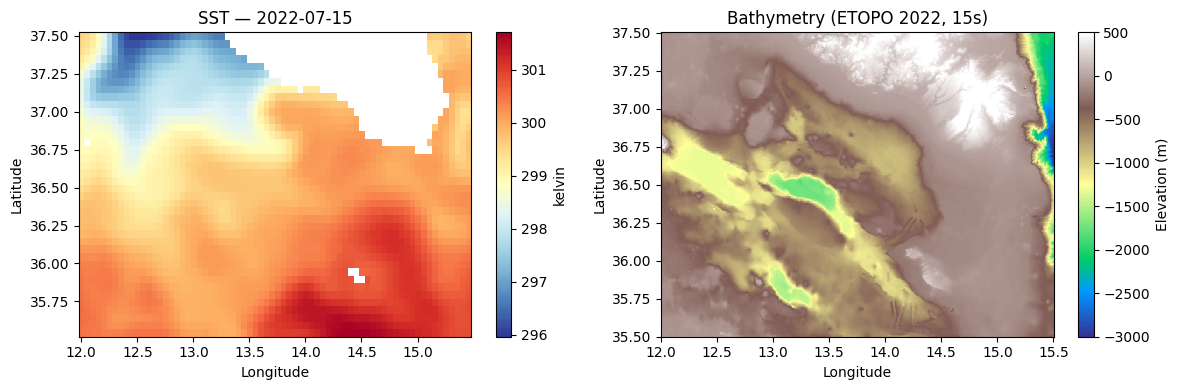

In [13]:
import matplotlib.pyplot as plt

FIG_DIR = Path("figs"); FIG_DIR.mkdir(exist_ok=True)
sst_day = sst.sel(time="2022-07-15", method="nearest")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

im0 = axes[0].pcolormesh(sst_day.longitude, sst_day.latitude, sst_day,
                         shading="auto", cmap="RdYlBu_r")
axes[0].set_title(f"SST — {str(sst_day.time.values)[:10]}")
axes[0].set_xlabel("Longitude"); axes[0].set_ylabel("Latitude")
plt.colorbar(im0, ax=axes[0], label=sst.attrs.get("units", ""))

im1 = axes[1].pcolormesh(bathy_lon, bathy_lat, elev,
                         shading="auto", cmap="terrain", vmin=-3000, vmax=500)
axes[1].set_title("Bathymetry (ETOPO 2022, 15s)")
axes[1].set_xlabel("Longitude"); axes[1].set_ylabel("Latitude")
plt.colorbar(im1, ax=axes[1], label="Elevation (m)")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_sst_and_bathy.png", dpi=150)
plt.show()

---
## Predictor roster (for Stage 8 — **do not download now**)

Locate, but don't fetch. Full descriptions are in `PLAN.md` Stage 3.

| Group | Product family (stable) | Why we want it |
|---|---|---|
| Wind reanalysis | ERA5 (CDS, via `cdsapi`) | Gap-free hourly wind, basin-scale forcing |
| Wind satellite | `WIND_GLO_PHY_L3_MY_012_005` | Direct scatterometer wind, sharper coastal gradients |
| Waves | `MEDSEA_MULTIYEAR_WAV_006_012` | Wave height/period — surface mixing proxy |
| Salinity / currents / SSH / temp / MLD | `MEDSEA_MULTIYEAR_PHY_006_004` | Atlantic-Ionian Stream (AIS) advection — dominant offshore driver |
| SLA / geostrophy | `SEALEVEL_EUR_PHY_L4_MY_008_068` | AIS proxy via altimetry |
| Optics / transparency | within `OCEANCOLOUR_MED_BGC_L3_MY_009_143` | `KD490`, `PAR` — light availability |
| BGC (optional, no `chl`) | `MEDSEA_MULTIYEAR_BGC_006_008` | Nutrients, oxygen — **never** include `chl` (circular) |

Skip this whole stack for now. Get the pipeline working with CHL + SST + bathy first.

---
## Next: `04-Build-Supervised.ipynb`

Turns the three cubes (CHL, SST, bathy) into a tidy `(features at t) → (target at t+h)` table for h ∈ {1..7}. This is where most silent bugs are born — Stage 4 includes a leakage assert that catches them.